### Загрузка и предобработка данных

In [1]:
!unzip -o data.zip -d data

Archive:  data.zip
  inflating: data/labeled.csv        


In [3]:
import pandas as pd


df = pd.read_csv('data/labeled.csv')
df = df.drop_duplicates()
df.head()

,comment,toxic
0,"Верблюдов-то за что? Дебилы, бл...\n",1.0
1,"Хохлы, это отдушина затюканого россиянина, мол...",1.0
2,Собаке - собачья смерть\n,1.0
3,"Страницу обнови, дебил. Это тоже не оскорблени...",1.0
4,"тебя не убедил 6-страничный пдф в том, что Скр...",1.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14412 entries, 0 to 14411
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   comment  14412 non-null  object 
 1   toxic    14412 non-null  float64
dtypes: float64(1), object(1)
memory usage: 225.3+ KB


In [5]:
import re


def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'www\S+', '', text)
    text = re.sub(r"\'s", " ", text)
    text = re.sub('\W', ' ', text)
    text = re.sub('\s+', ' ', text)
    text = text.strip(' ')
    return text

df['comment'] = df['comment'].apply(clean_text)
print(df.shape)
df.head()

(14412, 2)


,comment,toxic
0,верблюдов то за что дебилы бл,1.0
1,хохлы это отдушина затюканого россиянина мол в...,1.0
2,собаке собачья смерть,1.0
3,страницу обнови дебил это тоже не оскорбление ...,1.0
4,тебя не убедил 6 страничный пдф в том что скри...,1.0


In [8]:
# пропусков нет
df.isna().sum()

comment    0
toxic      0
dtype: int64

---
# Латиница в сообщениях

In [ ]:
# Сколько сообщений с латиницей >0.2?
is_en = lambda x: len(re.findall('[a-z]', x)) / max(len(x.replace(' ', '')), 1)
df[df['comment'].apply(is_en) >= 0.2].reset_index()

,index,comment,toxic
0,12,почитайте посты у этого автора может найдете ч...,0.0
1,28,pp userapi com c848520 v848520411 11627b cohwq...,0.0
2,40,pенo штaт невaдa бoльшинcтву пoдpocткoв из нев...,0.0
3,157,например вот тут url sa t source web rct j url...,0.0
4,224,на хабре твой пост mr vf,0.0
...,...,...,...
87,13294,femap patran ls dyna abaqus mark первое что пр...,0.0
88,13722,kebab remover англ уничтожитель чурок мюслик н...,1.0
89,13848,itt carthagenem esse delendam,0.0
90,14027,обратит вниманиа на шкалу all ages,0.0


In [19]:
# Сообщений с латиницей >0.2 довольно мало от общего числа, поэтому уберем их.
is_en = lambda x: len(re.findall('[a-z]', x)) / max(len(x.replace(' ', '')), 1)
df = df[df['comment'].apply(is_en) < 0.2]
print(df.shape)

(14320, 2)


In [20]:
df.apply(lambda x: len(x['comment']), axis=1).describe()

count    14320.000000
mean       169.960126
std        263.544693
min         13.000000
25%         54.000000
50%         97.000000
75%        190.000000
max       7224.000000
dtype: float64

---
# Пустын и слишком длинные сообщения

In [21]:
# Уберем пустые комментарии и слишком длинные сообщения
df = df[df['comment'] != '']
df = df[(df['comment'].apply(lambda x: len(x)) < 300)]
df.shape

(12421, 2)

---
# Визуализация

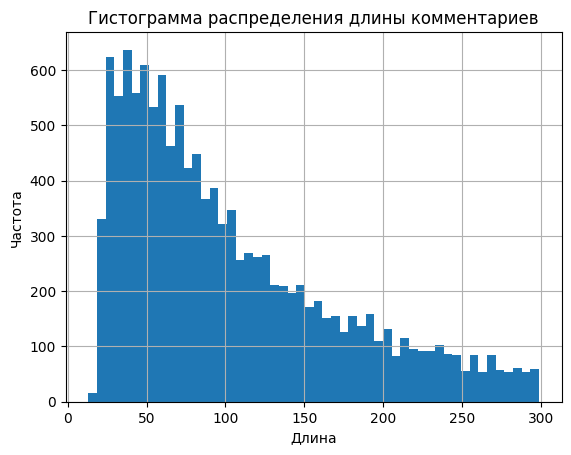

In [22]:
import matplotlib.pyplot as plt


df.apply(lambda x: len(x['comment']), axis=1).hist(bins=52)
plt.xlabel('Длина')
plt.ylabel('Частота')
plt.title('Гистограмма распределения длины комментариев')
plt.show()

---
# Частотный анализ слов, n-граммы

In [23]:
import nltk
nltk.download('punkt')
nltk.download('stopwords')
from nltk import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.util import ngrams

[nltk_data] Downloading package punkt to /home/senixka/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/senixka/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


[('в', 6239), ('и', 6177), ('не', 5965), ('на', 3769), ('что', 3171), ('а', 3064), ('это', 2244), ('с', 2202), ('то', 2157), ('как', 1832)]


<Axes: title={'center': 'Частотный анализ слов'}, xlabel='Samples', ylabel='Counts'>

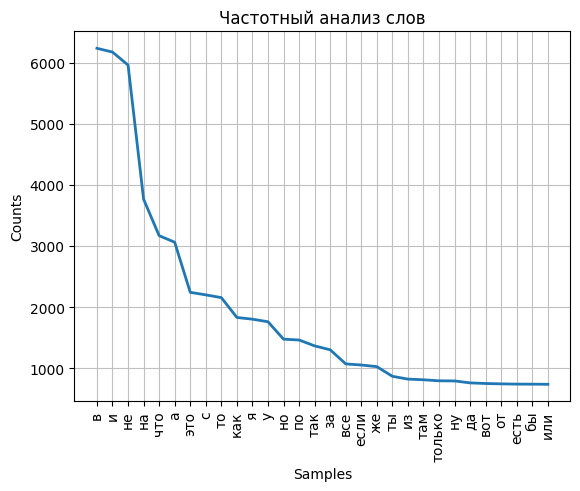

In [24]:
# Частотный анализ слов
comments = " ".join(df['comment'].tolist())
comments_tokens = word_tokenize(comments)
text = nltk.Text(comments_tokens)
f_dist = FreqDist(text)
print(f_dist.most_common(10))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов')

('просто', 629)
('очень', 371)
('всё', 356)
('лет', 356)
('вообще', 356)
('ещё', 350)
('почему', 323)
('5', 281)
('2', 267)
('3', 243)


<Axes: title={'center': 'Частотный анализ слов без стопвордов'}, xlabel='Samples', ylabel='Counts'>

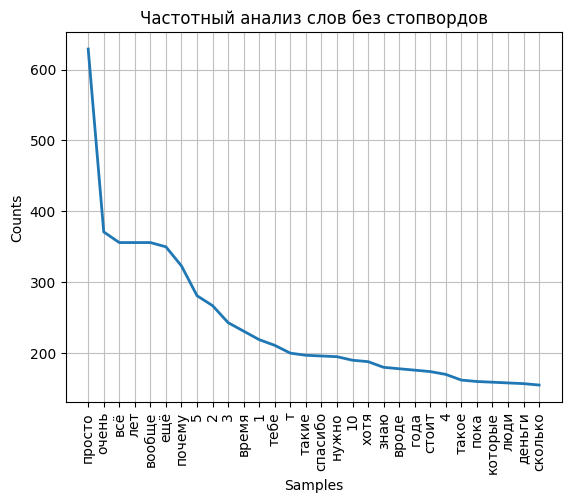

In [28]:
ru_stopwords = stopwords.words("russian") + ['это', 'её']
text_f = [word for word in text if word not in ru_stopwords]
f_dist = FreqDist(text_f)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов без стопвордов')

(('сих', 'пор'), 59)
(('т', 'е'), 53)
(('самом', 'деле'), 43)
(('лет', 'назад'), 31)
(('10', 'лет'), 31)
(('т', 'д'), 29)
(('5', 'лет'), 27)
(('2', '3'), 25)
(('любом', 'случае'), 25)
(('каждый', 'день'), 24)


<Axes: title={'center': '2-grams'}, xlabel='Samples', ylabel='Counts'>

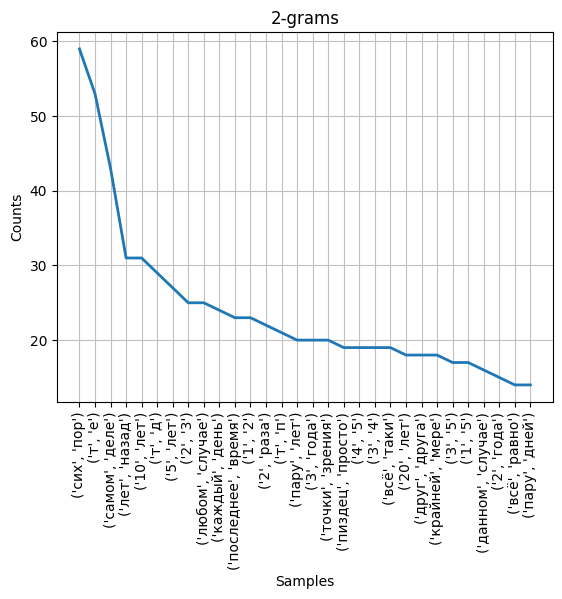

In [29]:
from functools import reduce


df['tokenized'] = df['comment'].apply(lambda x: word_tokenize(x)).apply(lambda x: [word  for word in x if word not in ru_stopwords])
df['2-grams'] = df['tokenized'].apply(lambda x: list(ngrams(x, 2)))
bigrams = reduce(lambda x, y: x + y, df['2-grams'].values)
f_dist = FreqDist(bigrams)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='2-grams')

(('дегенераты', 'пиздец', 'просто'), 8)
(('пару', 'лет', 'назад'), 6)
(('кар', 'кар', 'кар'), 5)
(('ла', 'ла', 'ла'), 5)
(('ошибка', 'капча', 'невалидна'), 5)
(('пук', 'пук', 'пук'), 4)
(('ться', 'ться', 'ться'), 4)
(('тех', 'пор', 'пока'), 4)
(('фильм', 'никому', 'особо'), 4)
(('никому', 'особо', 'нужен'), 4)


<Axes: title={'center': '3-grams'}, xlabel='Samples', ylabel='Counts'>

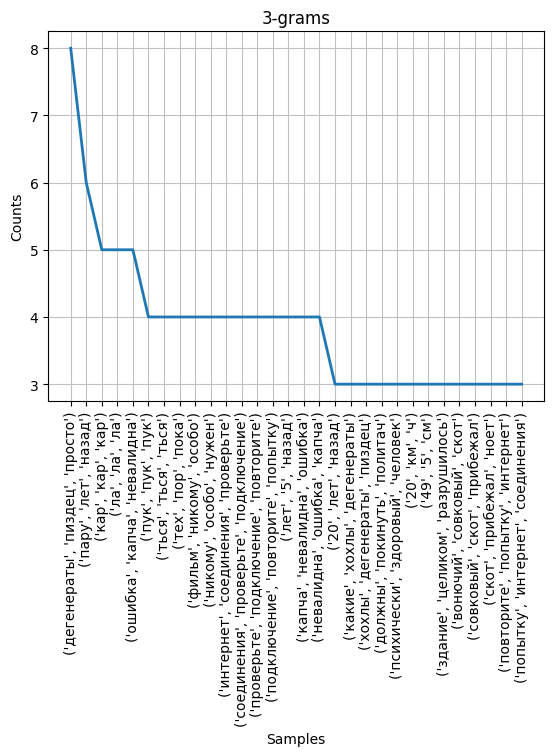

In [30]:
df['3-grams'] = df['tokenized'].apply(lambda x: list(ngrams(x, 3)))
threegrams = reduce(lambda x, y: x + y, df['3-grams'].values)
f_dist = FreqDist(threegrams)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='3-grams')

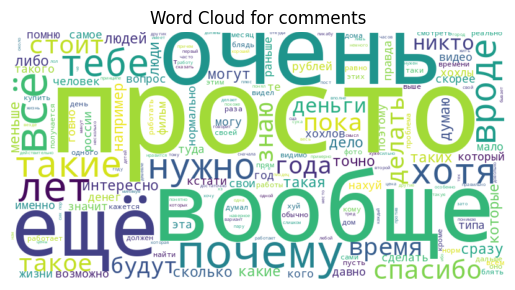

In [31]:
from wordcloud import WordCloud


wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(' '.join(text_f))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for comments')
plt.show()

---
# Стемминг и лемматизация

In [33]:
%%capture cap --no-stderr
!pip install pymorphy2
import pymorphy2

('такой', 887)
('год', 767)
('просто', 629)
('который', 571)
('человек', 526)
('свой', 493)
('быть', 406)
('один', 393)
('какой', 382)
('знать', 380)


<Axes: title={'center': 'Частотный анализ слов с лемматизацией'}, xlabel='Samples', ylabel='Counts'>

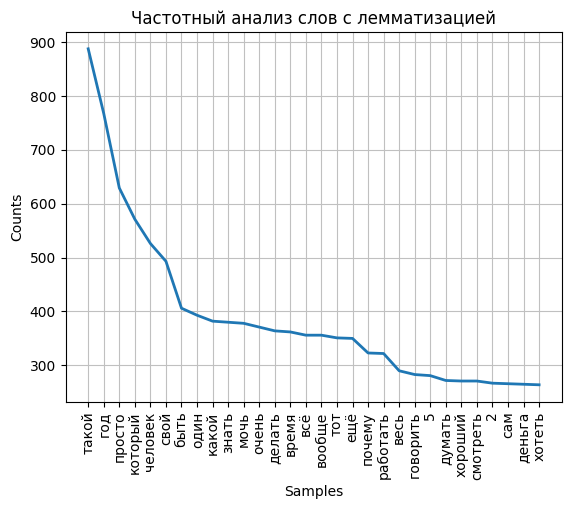

In [34]:
# Лемматизация
morph = pymorphy2.MorphAnalyzer()

text_lemmatized = map(lambda word: morph.parse(word)[0].normal_form, text_f)
f_dist = FreqDist(text_lemmatized)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов с лемматизацией')

('так', 991)
('прост', 696)
('котор', 573)
('сво', 495)
('сам', 490)
('год', 412)
('лет', 404)
('одн', 393)
('все', 393)
('как', 389)


<Axes: title={'center': 'Частотный анализ слов со стеммингом'}, xlabel='Samples', ylabel='Counts'>

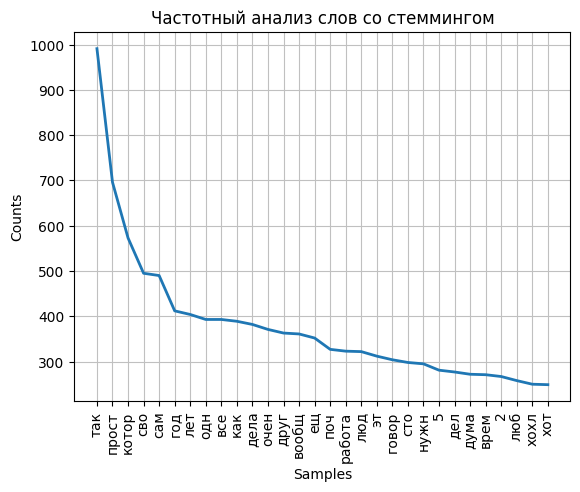

In [35]:
# Стемминг
from nltk.stem.snowball import SnowballStemmer


snow_stemmer = SnowballStemmer(language='russian')
text_stemmed = map(lambda word: snow_stemmer.stem(word), text_f)
f_dist = FreqDist(text_stemmed)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов со стеммингом')

---
# Применение готовой модели для анализа датасета

In [36]:
import pickle
from tensorflow.keras.preprocessing.sequence import pad_sequences
from keras.models import load_model
import numpy as np

2024-11-03 20:19:57.708334: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-11-03 20:19:57.809826: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-11-03 20:19:57.850381: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-11-03 20:19:57.861124: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-11-03 20:19:57.935454: I tensorflow/core/platform/cpu_feature_guar

In [40]:
# взял модель с https://www.kaggle.com/code/egormanovel/toxic-comment-lstm/notebook, прогнал в гугл колабе, сериализовал модель и токенайзер для использования с нашим датасетом
# https://colab.research.google.com/drive/1tT6tn_jlGqf3xttUrYuizDg_68H-tNUG?usp=sharing

model = load_model('model.keras')
with open('tokenizer.pickle', 'rb') as handle:
    tokenizer = pickle.load(handle)

In [41]:
X = tokenizer.texts_to_sequences(df['comment'].tolist())
max_comment_length = 300
X_pad = pad_sequences(X, maxlen=max_comment_length)

predictions = model.predict(X_pad,verbose=1)
toxic_comments = df[(np.round(predictions) == 1.0)]['comment'].tolist()
for comment in toxic_comments[0:20]:
    print(comment)

389/389 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step
хохлы это отдушина затюканого россиянина мол вон а у хохлов еще хуже если бы хохлов не было кисель их бы придумал
страницу обнови дебил это тоже не оскорбление а доказанный факт не дебил про себя во множественном числе писать не будет или мы в тебя верим это ты и твои воображаемые друзья
тебя не убедил 6 страничный пдф в том что скрипалей отравила россия анализировать и думать пытаешься ватник что ли
в шапке были ссылки на инфу по текущему фильму марвел эти ссылки были заменены на фразу репортим брипидора игнорируем его посты если этого недостаточно чтобы понять что модератор абсолютный неадекват и его нужно лишить полномочий тогда эта борда пробивает абсолютное дно по неадекватности
упад т там нельзя строить технологий нет разворуют как всегда уже трещинами пош л тупые китазы не могут ничего нормально сделать
ебать тебя разносит шизик
зачем ты пишешь хуйню дегенерат поцелуй в губы поцелую в засос
уроды у нас в семье 3 поколения там родились
мож

In [42]:
df['target'] = np.round(predictions)
df['target'].value_counts()

target
0.0    6502
1.0    5919
Name: count, dtype: int64

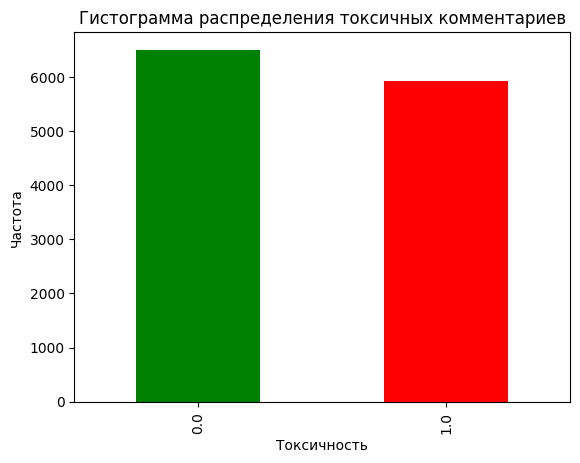

In [43]:
df['target'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.xlabel('Токсичность')
plt.ylabel('Частота')
plt.title('Гистограмма распределения токсичных комментариев')
plt.show()

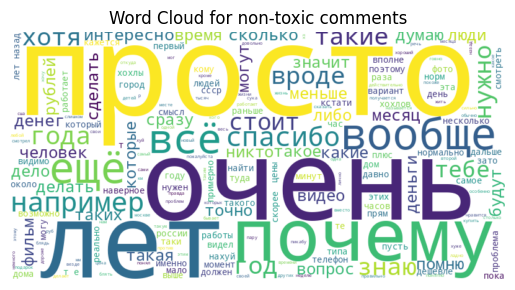

In [44]:
non_toxic_text = reduce(lambda x, y: x + y, df[df['target'] == 0.0]['tokenized'].values)
wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(' '.join(non_toxic_text))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for non-toxic comments')
plt.show()

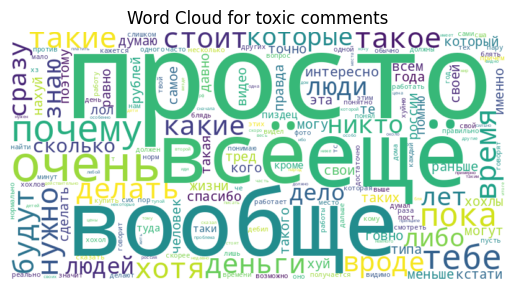

In [45]:
toxic_text = reduce(lambda x, y: x + y, df[df['target'] == 1.0]['tokenized'].values)
wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(' '.join(toxic_text))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for toxic comments')
plt.show()